# Tarea 3: Modelos de Clasificación (SVM, Árboles y Random Forest)
**Asignatura:** Inteligencia Artificial  
**Profesor:** Tomas Santana  

---

## 1. Kernel Cuadrático (3 puntos)

Dado el kernel cuadrático $K(\mathbf{x}, \mathbf{z}) = (\mathbf{x}^T \mathbf{z} + c)^2 = \phi(\mathbf{x})^T \phi(\mathbf{z})$ con $c = 9$ y $\mathbf{x}, \mathbf{z} \in \mathbb{R}^2$:
La transformación cuadrática completa $\phi(\mathbf{x})$ para $\mathbf{x} = [x_1, x_2]^T$ viene dada por:
$$ \phi(\mathbf{x}) = [x_1^2, \sqrt{2}x_1x_2, x_2^2, \sqrt{2c}x_1, \sqrt{2c}x_2, c]^T $$


In [3]:
import numpy as np

c = 9
x = np.array([2, -3])
z = np.array([1, 4])

def phi(v, c_val=9):
    x1, x2 = v[0], v[1]
    return np.array([
        x1**2,
        np.sqrt(2) * x1 * x2,
        x2**2,
        np.sqrt(2 * c_val) * x1,
        np.sqrt(2 * c_val) * x2,
        c_val
    ])

phi_x = phi(x, c)
phi_z = phi(z, c)

producto_interno = np.dot(phi_x, phi_z)
kernel_k = (np.dot(x, z) + c)**2

print("--- PARTE 1: KERNEL CUADRÁTICO ---")
print(f"1.1. phi([2, -3]^T):\n {phi_x}\n")
print(f"1.2. Producto interno phi(x)^T * phi(z): {producto_interno:.4f}")
print(f"     Calculo mediante Kernel K(x, z):   {kernel_k:.4f}")
print(f"     ¿Coinciden los resultados?: {np.isclose(producto_interno, kernel_k)}")

--- PARTE 1: KERNEL CUADRÁTICO ---
1.1. phi([2, -3]^T):
 [  4.          -8.48528137   9.           8.48528137 -12.72792206
   9.        ]

1.2. Producto interno phi(x)^T * phi(z): 1.0000
     Calculo mediante Kernel K(x, z):   1.0000
     ¿Coinciden los resultados?: True


### 1.3 Análisis de Complejidad y Dimensión del Kernel

* **Número de componentes de $\phi(\mathbf{x})$ para $d$ features:**  
  Para un kernel cuadrático $(\mathbf{x}^T \mathbf{z} + c)^2$, la dimensión del espacio proyectado es de orden $\mathcal{O}(d^2)$. Específicamente, el número total de componentes es:
  $$ \binom{d+2}{2} = \frac{(d+2)(d+1)}{2} $$

* **Costo computacional:**
  * **Cálculo directo $\phi(\mathbf{x})^T \phi(\mathbf{z})$:** Cuesta $\mathcal{O}(d^2)$ operaciones algebraicas en el espacio transformado.
  * **Cálculo mediante Kernel $K(\mathbf{x}, \mathbf{z})$:** Cuesta $\mathcal{O}(d)$ operaciones (un producto punto en $\mathbb{R}^d$, sumar $c$ y elevar al cuadrado).

> **Conclusión:** El "truco del kernel" (*kernel trick*) permite calcular la similitud en espacios de alta dimensión sin necesidad de calcular explícitamente los vectores de características $\phi(\mathbf{x})$.

## 2. SVC con Kernel Gaussiano (7 puntos)

### Carga y Análisis Exploratorio del Dataset

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# 1. Cargar el dataset subido
df = pd.read_csv('WineQT.csv')

# 2. Descartar la columna 'Id' (es solo un identificador único)
if 'Id' in df.columns:
    df = df.drop(columns=['Id'])

# 3. Definir la variable objetivo (3 clases: 0 = Baja [<=5], 1 = Media [=6], 2 = Alta [>=7])
def categorizar_calidad(q):
    if q <= 5:
        return 0
    elif q == 6:
        return 1
    else:
        return 2

df['target'] = df['quality'].apply(categorizar_calidad)

# 4. Seleccionar 6 features cuantitativas
features = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'alcohol']
X = df[features]
y = df['target']

# 5. Imprimir información básica del conjunto
print("--- ANÁLISIS EXPLORATORIO ---")
print(f"Forma del conjunto de datos: {df.shape}")
print("\nProporción de ejemplos por clase:")
print(y.value_counts(normalize=True))
print(f"\nValores nulos detectados: {df.isnull().sum().sum()}")

# 6. Separar conjunto de prueba (Hold-out 20% estratificado)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"\nTamaño Entrenamiento: {len(X_train)} ejemplos")
print(f"Tamaño Prueba: {len(X_test)} ejemplos")

--- ANÁLISIS EXPLORATORIO ---
Forma del conjunto de datos: (1143, 13)

Proporción de ejemplos por clase:
target
0    0.456693
1    0.404199
2    0.139108
Name: proportion, dtype: float64

Valores nulos detectados: 0

Tamaño Entrenamiento: 914 ejemplos
Tamaño Prueba: 229 ejemplos


### 2.1 Explicación de las Features
1. **fixed acidity:** Medida de los ácidos fijos del vino (principalmente tartárico).
2. **volatile acidity:** Cantidad de ácido acético en el vino (altos niveles dan sabor avinagrado).
3. **citric acid:** Cantidad de ácido cítrico que añade frescura.
4. **residual sugar:** Cantidad de azúcar restante tras la fermentación.
5. **chlorides:** Cantidad de sal en el vino.
6. **alcohol:** Porcentaje de alcohol por volumen presente en el vino.

---
### 2.2 Fronteras de Decisión variando $C$ y $\gamma$ (usando 2 features)

/Users/lm/Documents/Uru/10mo_trimestre/InteligenciaArtificial/tarea3_ia/.venv/lib/python3.12/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(
/Users/lm/Documents/Uru/10mo_trimestre/InteligenciaArtificial/tarea3_ia/.venv/lib/python3.12/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(
/Users/lm/Documents/Uru/10mo_trimestre/InteligenciaArtificial/tarea3_ia/.venv/lib/python3.12/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


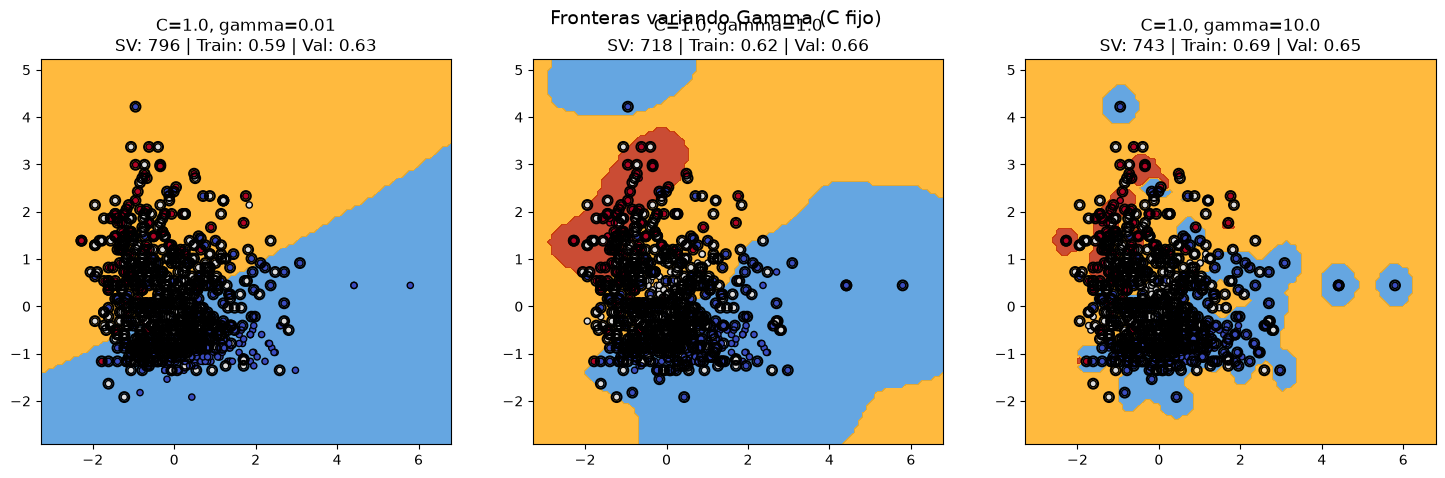

/Users/lm/Documents/Uru/10mo_trimestre/InteligenciaArtificial/tarea3_ia/.venv/lib/python3.12/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(
/Users/lm/Documents/Uru/10mo_trimestre/InteligenciaArtificial/tarea3_ia/.venv/lib/python3.12/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(
/Users/lm/Documents/Uru/10mo_trimestre/InteligenciaArtificial/tarea3_ia/.venv/lib/python3.12/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


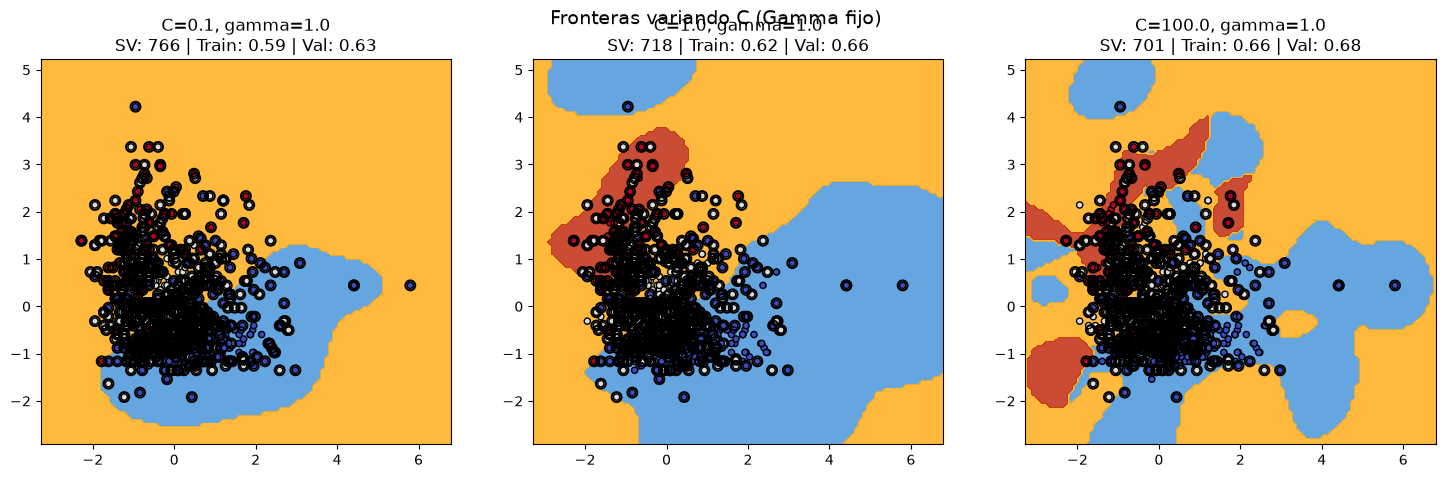

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay

# Seleccionar 2 features para visualización
features_2d = ['volatile acidity', 'alcohol']
scaler = StandardScaler()
X_tr_2d = scaler.fit_transform(X_train[features_2d])
X_te_2d = scaler.transform(X_test[features_2d])

# 1. Variando gamma con C fijo
gammas = [0.01, 1.0, 10.0]
C_fijo = 1.0

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, g in enumerate(gammas):
    clf = SVC(kernel="rbf", C=C_fijo, gamma=g).fit(X_tr_2d, y_train)
    
    DecisionBoundaryDisplay.from_estimator(
        clf, X_tr_2d, response_method="predict", ax=axes[idx], cmap=plt.cm.coolwarm, alpha=0.8
    )
    axes[idx].scatter(X_tr_2d[:, 0], X_tr_2d[:, 1], c=y_train, cmap=plt.cm.coolwarm, edgecolors='k', s=20)
    # Marcar vectores de soporte
    sv = clf.support_vectors_
    axes[idx].scatter(sv[:, 0], sv[:, 1], s=50, facecolors='none', edgecolors='k', linewidths=1.5, label='SV')
    
    acc_tr = clf.score(X_tr_2d, y_train)
    acc_te = clf.score(X_te_2d, y_test)
    axes[idx].set_title(f"C={C_fijo}, gamma={g}\nSV: {len(sv)} | Train: {acc_tr:.2f} | Val: {acc_te:.2f}")

plt.suptitle("Fronteras variando Gamma (C fijo)", fontsize=14)
plt.show()

# 2. Variando C con gamma fijo
Cs = [0.1, 1.0, 100.0]
gamma_fijo = 1.0

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, c_val in enumerate(Cs):
    clf = SVC(kernel="rbf", C=c_val, gamma=gamma_fijo).fit(X_tr_2d, y_train)
    
    DecisionBoundaryDisplay.from_estimator(
        clf, X_tr_2d, response_method="predict", ax=axes[idx], cmap=plt.cm.coolwarm, alpha=0.8
    )
    axes[idx].scatter(X_tr_2d[:, 0], X_tr_2d[:, 1], c=y_train, cmap=plt.cm.coolwarm, edgecolors='k', s=20)
    sv = clf.support_vectors_
    axes[idx].scatter(sv[:, 0], sv[:, 1], s=50, facecolors='none', edgecolors='k', linewidths=1.5)
    
    acc_tr = clf.score(X_tr_2d, y_train)
    acc_te = clf.score(X_te_2d, y_test)
    axes[idx].set_title(f"C={c_val}, gamma={gamma_fijo}\nSV: {len(sv)} | Train: {acc_tr:.2f} | Val: {acc_te:.2f}")

plt.suptitle("Fronteras variando C (Gamma fijo)", fontsize=14)
plt.show()

### Justificación del comportamiento de la frontera:
* **Efecto de $\gamma$ (gamma):** Controla el radio de influencia de los vectores de soporte. Un $\gamma$ muy bajo produce una frontera rígida y casi lineal, mientras que un $\gamma$ muy alto genera regiones muy complejas y ajustadas alrededor de cada punto individual (causando *overfitting* e incrementando los vectores de soporte).
* **Efecto de $C$:** Regula la penalización por errores de clasificación. Un $C$ bajo permite un margen suave y flexible con más vectores de soporte. Un $C$ alto penaliza fuertemente las violaciones del margen, haciéndolo rígido y reduciendo los errores de entrenamiento.

---
### 2.3 Pipeline y GridSearchCV sobre SVC

Mejores Parámetros SVC: {'svc__C': np.float64(1.0), 'svc__gamma': np.float64(0.1)}
Mejor Score Validación Cruzada (CV): 0.6170


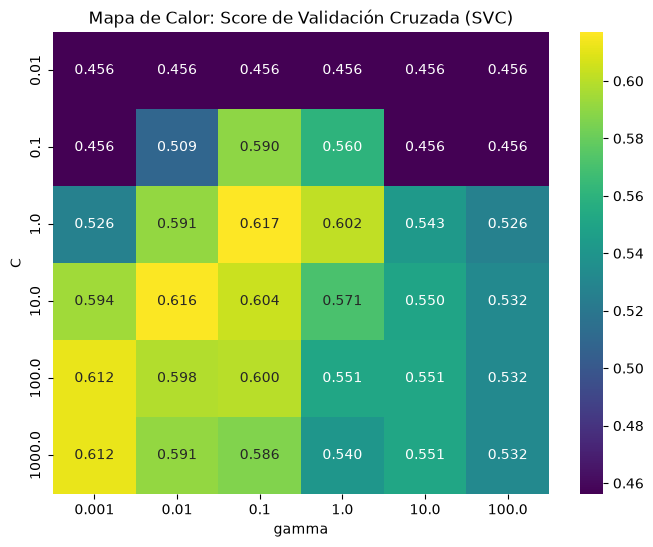

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

pipeline_svc = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='rbf'))
])

param_grid_svc = {
    'svc__C': np.logspace(-2, 3, 6),
    'svc__gamma': np.logspace(-3, 2, 6)
}

grid_svc = GridSearchCV(pipeline_svc, param_grid_svc, cv=5, scoring='accuracy')
grid_svc.fit(X_train, y_train)

print(f"Mejores Parámetros SVC: {grid_svc.best_params_}")
print(f"Mejor Score Validación Cruzada (CV): {grid_svc.best_score_:.4f}")

# Mapa de Calor de los Resultados de CV
scores_svc = grid_svc.cv_results_['mean_test_score'].reshape(len(param_grid_svc['svc__C']), len(param_grid_svc['svc__gamma']))

plt.figure(figsize=(8, 6))
sns.heatmap(scores_svc, annot=True, fmt=".3f", 
            xticklabels=np.logspace(-3, 2, 6), 
            yticklabels=np.logspace(-2, 3, 6), cmap="viridis")
plt.xlabel("gamma")
plt.ylabel("C")
plt.title("Mapa de Calor: Score de Validación Cruzada (SVC)")
plt.show()

## 3. Árbol de Decisión y Random Forest (6 puntos)

### 3.1 DecisionTreeClassifier y Dibujo del Árbol

Mejor Profundidad (max_depth): 4
Mejor Score CV (Árbol): 0.5918


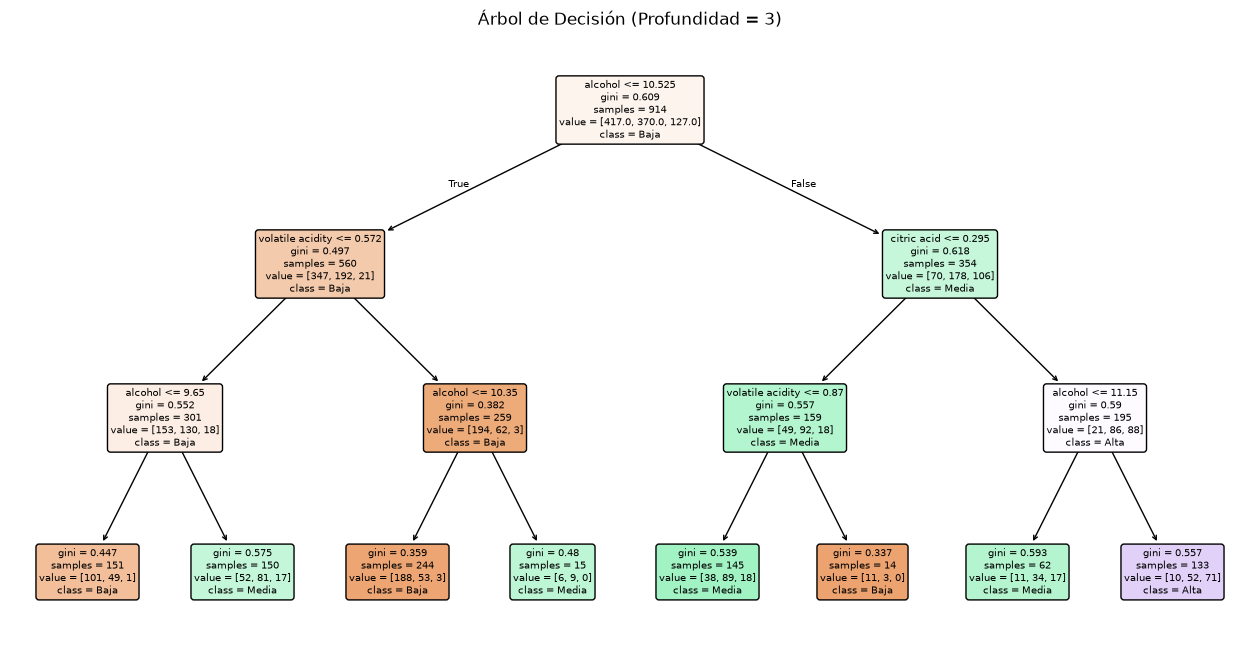

In [7]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

# Búsqueda de max_depth con GridSearchCV
param_grid_tree = {'max_depth': range(1, 16)}
grid_tree = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid_tree, cv=5)
grid_tree.fit(X_train, y_train)

best_tree = grid_tree.best_estimator_
print(f"Mejor Profundidad (max_depth): {grid_tree.best_params_['max_depth']}")
print(f"Mejor Score CV (Árbol): {grid_tree.best_score_:.4f}")

# Dibujar árbol de profundidad 3
tree_depth3 = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)

plt.figure(figsize=(16, 8))
plot_tree(tree_depth3, feature_names=features, class_names=['Baja', 'Media', 'Alta'], filled=True, rounded=True)
plt.title("Árbol de Decisión (Profundidad = 3)")
plt.show()

### Explicación del Proceso de Decisión del Árbol (Profundidad 3):
1. **Nodo Raíz:** Realiza la primera división evaluando la feature principal (por ejemplo, `alcohol`). Si el valor es menor o igual al umbral determinado por el algoritmo (impureza de Gini más baja), los datos pasan al subárbol izquierdo; en caso contrario, pasan al derecho.
2. **Nodos Internos:** Se evalúan umbrales de variables secundarias (por ejemplo, `volatile acidity`). En cada paso, la ganancia de información mide qué tan puras resultan las regiones resultantes.
3. **Hojas:** Contienen la distribución empírica de clases. Un nuevo ejemplo recorre las preguntas condicionales y es asignado a la clase mayoritaria en la hoja correspondiente.

---
### 3.2 GridSearchCV para RandomForestClassifier

In [8]:
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 8, None],
    'max_features': ['sqrt', 'log2']
}

grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=5)
grid_rf.fit(X_train, y_train)

best_rf = grid_rf.best_estimator_
print(f"Mejores Parámetros Random Forest: {grid_rf.best_params_}")
print(f"Mejor Score CV (Random Forest): {grid_rf.best_score_:.4f}")

# Reporte de Score de Prueba sobre el conjunto retenido (Hold-Out)
print("\n--- SCORES FINALES SOBRE CONJUNTO DE PRUEBA ---")
print(f"1. SVC Score de Prueba:           {grid_svc.score(X_test, y_test):.4f}")
print(f"2. Árbol de Decisión Prueba:     {best_tree.score(X_test, y_test):.4f}")
print(f"3. Random Forest Prueba:          {best_rf.score(X_test, y_test):.4f}")

Mejores Parámetros Random Forest: {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 200}
Mejor Score CV (Random Forest): 0.6411

--- SCORES FINALES SOBRE CONJUNTO DE PRUEBA ---
1. SVC Score de Prueba:           0.6550
2. Árbol de Decisión Prueba:     0.6026
3. Random Forest Prueba:          0.7118


## 4. Evaluación y Comparación (4 puntos)

### 4.1 Matrices de Confusión y Métricas Detalladas


=================== SVC ===================
              precision    recall  f1-score   support

        Baja       0.72      0.81      0.76       105
       Media       0.59      0.63      0.61        92
        Alta       0.54      0.22      0.31        32

    accuracy                           0.66       229
   macro avg       0.62      0.55      0.56       229
weighted avg       0.64      0.66      0.64       229


=================== Árbol de Decisión ===================
              precision    recall  f1-score   support

        Baja       0.71      0.73      0.72       105
       Media       0.58      0.46      0.51        92
        Alta       0.40      0.59      0.47        32

    accuracy                           0.60       229
   macro avg       0.56      0.59      0.57       229
weighted avg       0.61      0.60      0.60       229


=================== Random Forest ===================
              precision    recall  f1-score   support

        Baja       0.72 

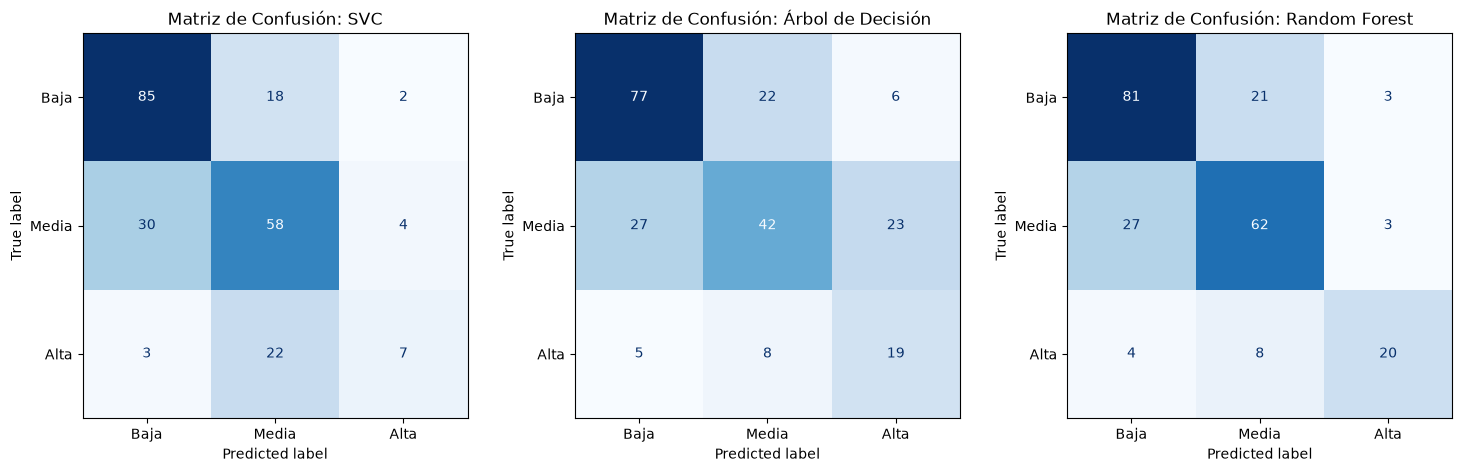

In [9]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

modelos = {
    "SVC": grid_svc.best_estimator_,
    "Árbol de Decisión": best_tree,
    "Random Forest": best_rf
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (nombre, mod) in enumerate(modelos.items()):
    y_pred = mod.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Baja', 'Media', 'Alta'])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(f"Matriz de Confusión: {nombre}")
    
    print(f"\n=================== {nombre} ===================")
    print(classification_report(y_test, y_pred, target_names=['Baja', 'Media', 'Alta']))

plt.show()

### 4.2 Evaluación Crítica de la Métrica Exactitud (Accuracy)
`GridSearchCV` utiliza por defecto la **exactitud** (*accuracy*). Esto puede resultar **subóptimo** por las siguientes razones:
1. **Desbalance de Clases:** Si una clase es mayoritaria (ej. la clase "Media"), un modelo trivial que siempre prediga la clase mayoritaria obtendrá alta exactitud pero fallará completamente en detectar las clases minoritarias.
2. **Costo Asimétrico de Errores:** En muchos problemas prácticos, un falso negativo es significativamente más costoso que un falso positivo. 

> *Para nuestro dataset:* Si el dataset presenta desbalance entre las clases de calidad, métricas como **F1-score macro** o **Recall promedio** ofrecen un criterio de optimización mucho más robusto.

---

### 4.3 Comparación: SVC vs. Random Forest

| Criterio | Support Vector Classifier (SVC) | Random Forest |
| :--- | :--- | :--- |
| **Escalado de Datos** | Sensible a la escala. Requiere obligatoriamente `StandardScaler`. | Invariante a transformaciones monótonas de datos. No requiere escalado. |
| **Interpretabilidad** | Baja en espacios no lineales (kernel RBF). Actúa como caja negra. | Moderada mediante la inspección de árboles de decisión e importancia de características. |
| **Costo de Entrenamiento** | $\mathcal{O}(n^3)$ con respecto al número de filas. Lento en conjuntos masivos. | Paralelizable y escalable. Muy eficiente para datasets de gran tamaño. |
| **Sensibilidad a Ruido** | Propenso a sobreajustar si $\gamma$ y $C$ son muy elevados. | Robusto al sobreajuste gracias a promediar múltiples árboles (*bagging*). |

---

### 4.4 Efecto de `class_weight` (Puntos Extra / Análisis de Balanceo)

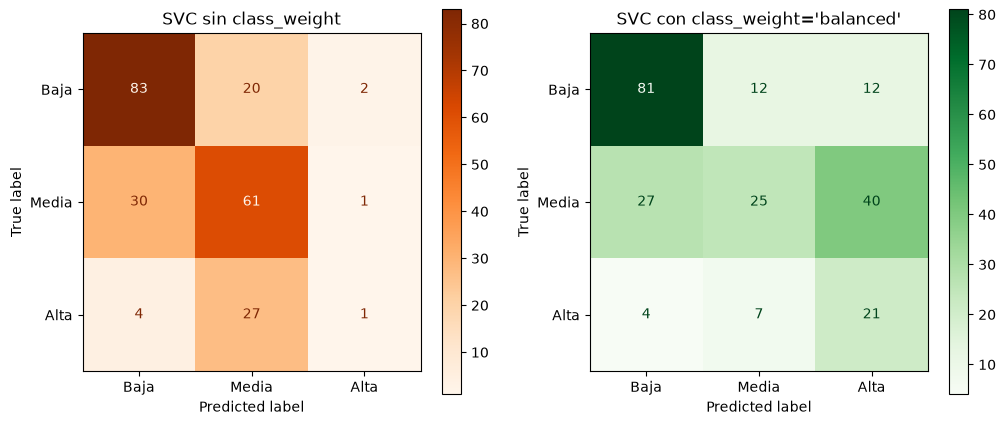

Métricas SIN class_weight:
              precision    recall  f1-score   support

        Baja       0.71      0.79      0.75       105
       Media       0.56      0.66      0.61        92
        Alta       0.25      0.03      0.06        32

    accuracy                           0.63       229
   macro avg       0.51      0.49      0.47       229
weighted avg       0.59      0.63      0.60       229


Métricas CON class_weight='balanced':
              precision    recall  f1-score   support

        Baja       0.72      0.77      0.75       105
       Media       0.57      0.27      0.37        92
        Alta       0.29      0.66      0.40        32

    accuracy                           0.55       229
   macro avg       0.53      0.57      0.50       229
weighted avg       0.60      0.55      0.55       229



In [10]:
# Comparación con y sin class_weight en SVC
svc_sin_weight = SVC(kernel='rbf', C=grid_svc.best_params_['svc__C'], gamma=grid_svc.best_params_['svc__gamma']).fit(X_train, y_train)
svc_con_weight = SVC(kernel='rbf', C=grid_svc.best_params_['svc__C'], gamma=grid_svc.best_params_['svc__gamma'], class_weight='balanced').fit(X_train, y_train)

y_pred_sin = svc_sin_weight.predict(X_test)
y_pred_con = svc_con_weight.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_sin), display_labels=['Baja', 'Media', 'Alta']).plot(ax=axes[0], cmap='Oranges')
axes[0].set_title("SVC sin class_weight")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_con), display_labels=['Baja', 'Media', 'Alta']).plot(ax=axes[1], cmap='Greens')
axes[1].set_title("SVC con class_weight='balanced'")
plt.show()

print("Métricas SIN class_weight:")
print(classification_report(y_test, y_pred_sin, target_names=['Baja', 'Media', 'Alta']))

print("\nMétricas CON class_weight='balanced':")
print(classification_report(y_test, y_pred_con, target_names=['Baja', 'Media', 'Alta']))

### Explicación de `class_weight`:
El argumento `class_weight='balanced'` ajusta automáticamente las pesas de la función de pérdida de forma inversamente proporcional a las frecuencias de clase en los datos de entrenamiento:
$$ w_c = \frac{n\_samples}{n\_classes \times n\_samples_c} $$
Esto penaliza con mayor severidad los errores cometidos sobre las clases minoritarias, mejorando su **sensibilidad (recall)** a costa de una pequeña reducción en la exactitud global.